# Clustering a Multi-Asset Portfolio by Co-Movement

*Can a data-driven clustering recover economically meaningful asset groups, and are those groups stable enough to build portfolios on?*

| Question | Finding | Section |
|---|---|---|
| Which correlation distance is a true metric? | √(½(1−ρ)) passes the triangle inequality on all 1,771 ETF triples; 1−ρ fails 151 (9%). | 1 |
| What does mutual information add to correlation? | It detects non-linear links that correlation misses (y = x²: normalised MI 0.67, \|ρ\| 0.02). On daily ETF returns it ranks pairs almost exactly like correlation (rank correlation 0.92). | 2–3 |
| How many groups do 23 ETFs form? | 4 on raw correlation: one risk-on block (all equities plus HYG, EMB, VNQ), Treasuries and IG bonds, gold and silver, oil and commodities. Removing the market factor first gives 8 groups and doubles agreement with asset classes (ARI 0.30 → 0.63). | 4, 6 |
| Does ONC recover clusters that are known? | Only when groups are equally strong. With unequal groups the plain stopping rule returns 2 clusters in every draw (ARI 0.34); recursively redoing a lone weak cluster lifts ARI to 0.67–0.95, still behind k-means or Ward with the best mean silhouette (0.87–1.00). | 5 |
| What do 90 stocks look like to ONC? | 2 clusters on every input (ARI 0.12–0.13 against sectors). k-means told the true k = 10 reaches ARI 0.43; the best ONC variant 0.27. | 6 |
| Are the clusters stable over time? | No. Across 2-year windows the ONC count moves between 2 and 7 and consecutive partitions agree at ARI 0.45 on average; a fixed k = 5 agrees at 0.84. | 7 |

**Use it when.** Building asset groups for risk budgeting, diversification checks or nested portfolio construction, or grouping correlated features before measuring their importance. Treat the automatic choice of k as a starting point and check it across windows.

**Method.** Distance √(½(1−ρ)); Optimal Number of Clusters (ONC): k-means on the distance matrix with k and the initialisation chosen by the silhouette t-statistic, then a recursive re-clustering of below-average clusters, kept only if it raises average cluster quality.

**Data.** Daily adjusted closes, Jan-2015 to Oct-2026 (2,970 days, Yahoo Finance): 23 multi-asset ETFs (US and international equity, bonds, real assets) and 90 US large-cap stocks in 10 sectors. Simple daily returns. Asset-class and sector labels follow a standard mapping and serve as a consistency check, not as ground truth.

**Contents.** 1 Distance metric · 2 Information vs correlation · 3 Real returns · 4 ONC on ETFs · 5 Simulation with known clusters · 6 Cleaning before clustering · 7 Stability · Conclusions

In [1]:
import sys, warnings
sys.path.insert(0, ".")
warnings.filterwarnings("ignore")

from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr, entropy
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score, silhouette_samples, mutual_info_score

import data_utils as du
import quant_tools as qt

du.set_style()
rng = np.random.default_rng(11)

etf = du.load_returns("etfs", log=False)
stk = du.load_returns("stocks", log=False)
etf_group = pd.Series(du.etf_map())[etf.columns]
stk_group = pd.Series(du.sector_map())[stk.columns]
print(f"ETFs: {etf.shape}, stocks: {stk.shape}, {etf.index[0].date()} to {etf.index[-1].date()}")

ETFs: (2970, 23), stocks: (2970, 90), 2015-01-05 to 2026-10-26


## 1 · Which distance is a true metric?

Clustering algorithms such as k-means and hierarchical linkage assume a **metric**: a distance that is zero only for identical items, symmetric, and obeys the triangle inequality d(a,c) ≤ d(a,b) + d(b,c). Without the triangle inequality, "close to close" no longer means close, and clusters can form around inconsistencies.

Correlation itself is a similarity, not a distance. Two conversions are common:
- d(ρ) = √(½(1 − ρ)). For standardised return series x and y, the Euclidean distance between them is √(2T(1 − ρ)), so this is a Euclidean distance up to a constant and inherits all metric properties. It runs from 0 (ρ = 1) to 1 (ρ = −1).
- d(ρ) = 1 − ρ. Simpler, but the square of a metric is not a metric.

Both are checked on every triple of the 23 ETFs.

In [2]:
def triangle_violations(dist):
    d = np.asarray(dist)
    n = len(d)
    bad = 0
    total = 0
    for i, j, k in combinations(range(n), 3):
        total += 1
        a, b, c = d[i, j], d[j, k], d[i, k]
        if a + b < c - 1e-12 or a + c < b - 1e-12 or b + c < a - 1e-12:
            bad += 1
    return bad, total

corr_etf = etf.corr()
d_metric = np.sqrt(0.5 * (1 - corr_etf.values))
d_naive = 1 - corr_etf.values
for name, d in [("sqrt(0.5 (1 - rho))", d_metric), ("1 - rho", d_naive)]:
    bad, total = triangle_violations(d)
    print(f"{name:22s} triangle violations: {bad} of {total} triples")

sqrt(0.5 (1 - rho))    triangle violations: 0 of 1771 triples
1 - rho                triangle violations: 151 of 1771 triples


- The square-root distance has zero violations across 1,771 triples; 1 − ρ breaks the triangle inequality in 151 of them (9%).
- Every clustering below uses √(½(1 − ρ)).

## 2 · What can correlation not see?

Correlation measures **linear** dependence only. A variable and its square can be perfectly linked and still show ρ ≈ 0, because the positive and negative halves cancel. Information theory measures any kind of dependence:
- **Entropy** H(X): the uncertainty in X, measured on a histogram.
- **Mutual information** I(X;Y) = H(X) + H(Y) − H(X,Y): how much knowing Y reduces the uncertainty in X. It is zero only for independent variables.
- **Variation of information** VI = H(X) + H(Y) − 2·I(X;Y), divided by the joint entropy H(X,Y): a true metric in [0, 1], 0 for identical information and 1 for independence.

Entropy depends on the number of histogram bins. Too few bins hide structure, too many make every bin sparse. The bin count here follows a formula that depends on the sample size and, for pairs, on their correlation, so the estimate does not rest on an arbitrary choice.

Controlled test: five known relationships, T = 5,000 observations.

                        normalised MI  normalised VI    |ρ|
linear (y = x + noise)          0.330          0.808  0.896
quadratic (y = x²)              0.666          0.684  0.016
sine (y = sin 3x)               0.315          0.833  0.045
absolute (y = |x|)              0.503          0.667  0.013
independent                     0.006          0.997  0.015


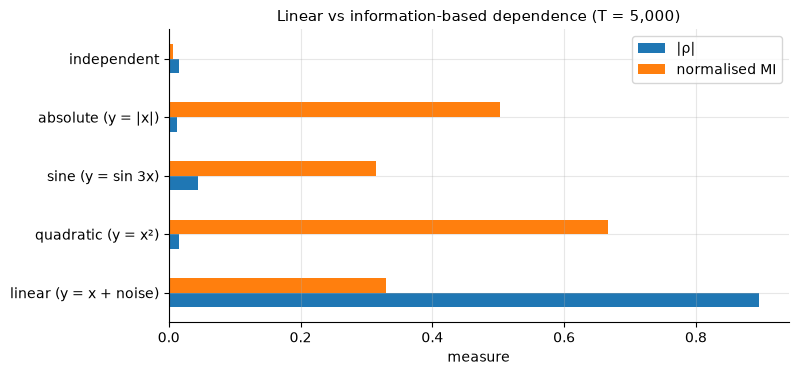

In [3]:
def num_bins(n_obs, corr=None):
    if corr is None:  # marginal
        z = (8 + 324 * n_obs + 12 * (36 * n_obs + 729 * n_obs ** 2) ** 0.5) ** (1 / 3.0)
        return int(round(z / 6.0 + 2.0 / (3 * z) + 1.0 / 3))
    return int(round(2 ** -0.5 * (1 + (1 + 24 * n_obs / (1.0 - corr ** 2)) ** 0.5) ** 0.5))

def info_measures(x, y, norm=True):
    """Mutual information, variation of information (both optionally normalised) and |rho|."""
    rho = np.corrcoef(x, y)[0, 1]
    b = num_bins(len(x), rho)
    cxy = np.histogram2d(x, y, bins=b)[0]
    mi_raw = mutual_info_score(None, None, contingency=cxy)
    hx = entropy(np.histogram(x, b)[0])
    hy = entropy(np.histogram(y, b)[0])
    vi = hx + hy - 2 * mi_raw
    if norm:
        return mi_raw / min(hx, hy), vi / (hx + hy - mi_raw), abs(rho)
    return mi_raw, vi, abs(rho)

n = 5000
x = rng.normal(size=n)
cases = {
    "linear (y = x + noise)": x + rng.normal(scale=0.5, size=n),
    "quadratic (y = x²)": x ** 2 + rng.normal(scale=0.1, size=n),
    "sine (y = sin 3x)": np.sin(3 * x) + rng.normal(scale=0.1, size=n),
    "absolute (y = |x|)": np.abs(x) + rng.normal(scale=0.1, size=n),
    "independent": rng.normal(size=n),
}
rows = {k: info_measures(x, y) for k, y in cases.items()}
tab = pd.DataFrame(rows, index=["normalised MI", "normalised VI", "|ρ|"]).T.round(3)
print(tab.to_string())

tab[["|ρ|", "normalised MI"]].plot.barh(figsize=(8, 3.8), title="Linear vs information-based dependence (T = 5,000)")
plt.xlabel("measure"); plt.show()

- For the three non-linear relationships \|ρ\| is 0.01–0.05, so correlation reports no link, while normalised MI is 0.67 (y = x²), 0.50 (y = \|x\|) and 0.32 (y = sin 3x).
- Independent data score about zero on both measures (MI 0.006, \|ρ\| 0.015), so neither invents dependence.
- For the linear relation \|ρ\| = 0.90 but normalised MI only 0.33. The two measures sit on different scales, so values are compared within a measure, never across.

## 3 · Does information add anything on real returns?

If daily asset returns carried strong non-linear links, mutual information would rank some pairs far higher than correlation does. Pairwise \|ρ\| and normalised MI are computed for all 253 ETF pairs. Daily returns are noisy and MI levels are small, so the comparison is between rankings.

253 pairs, rank correlation between |rho| and normalised MI: 0.92

Pairs where information ranks much higher than correlation:
  a   b  abs_rho   nmi  rank_rho  rank_nmi
TLT HYG    0.036 0.081     0.043     0.581
IEF HYG    0.104 0.100     0.186     0.609
VTV AGG    0.063 0.048     0.087     0.435
VUG IEF    0.092 0.050     0.162     0.458
TLT VNQ    0.043 0.041     0.059     0.344
SHY HYG    0.158 0.067     0.292     0.569


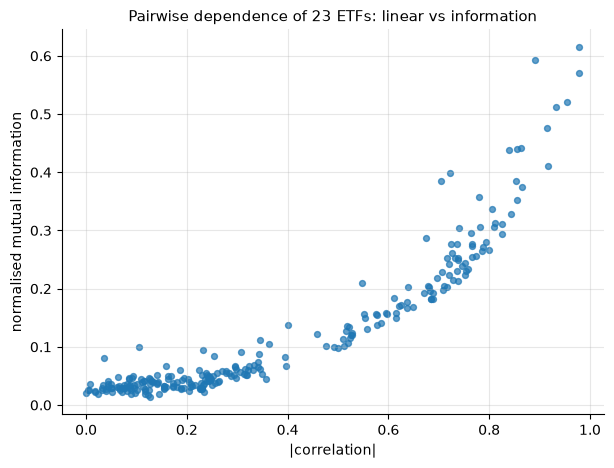

In [4]:
cols = list(etf.columns)
pairs = list(combinations(range(len(cols)), 2))
pair_df = pd.DataFrame(
    [(cols[i], cols[j], *info_measures(etf.iloc[:, i].values, etf.iloc[:, j].values)) for i, j in pairs],
    columns=["a", "b", "nmi", "nvi", "abs_rho"])
rank_corr = spearmanr(pair_df["abs_rho"], pair_df["nmi"]).statistic
print(f"{len(pair_df)} pairs, rank correlation between |rho| and normalised MI: {rank_corr:.2f}")

pair_df["rank_rho"] = pair_df["abs_rho"].rank(pct=True)
pair_df["rank_nmi"] = pair_df["nmi"].rank(pct=True)
pair_df["gap"] = pair_df["rank_nmi"] - pair_df["rank_rho"]
print("\nPairs where information ranks much higher than correlation:")
print(pair_df.sort_values("gap", ascending=False).head(6)[["a", "b", "abs_rho", "nmi", "rank_rho", "rank_nmi"]].round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(pair_df["abs_rho"], pair_df["nmi"], s=18, alpha=0.7)
ax.set(xlabel="|correlation|", ylabel="normalised mutual information", title="Pairwise dependence of 23 ETFs: linear vs information")
plt.show()

- Information and correlation agree closely: rank correlation 0.92 across 253 pairs, along a smooth convex curve.
- The pairs that information ranks higher are credit against rates (HYG with TLT, IEF and SHY) and a few equity/bond pairs. Their levels are small (HYG-TLT: \|ρ\| = 0.04, MI = 0.08). High-yield bonds behave like rates in calm markets and like equities in stress, a state-dependent link that a single correlation averages away.
- For daily liquid assets, correlation distance is sufficient for grouping. Information measures earn their extra cost on non-linear payoffs such as options.

## 4 · How many groups do the ETFs form?

k-means needs the number of clusters k in advance and depends on random starting points. ONC removes both choices.

**Silhouette.** For asset i, a = average distance to the members of its own cluster and b = average distance to the members of the nearest other cluster. Its silhouette is S = (b − a) / max(a, b): close to 1 when the asset sits well inside its cluster, near 0 on a border, negative when it is closer to another cluster.

**Quality of a partition.** ONC scores a partition by the **silhouette t-statistic**, mean(S) / std(S). The mean rewards tight clusters; dividing by the spread rewards partitions where every asset fits about equally well, rather than a few perfect fits and many poor ones.

**Algorithm.**
1. Describe each asset by its row of distances to all others, so two assets are similar when they relate to the rest of the universe in the same way.
2. Run k-means for every k from 2 up to a maximum, with several random starts each, and keep the partition with the highest t-statistic.
3. Score each cluster by the t-statistic of its own members. Clusters below the average are re-clustered with the same procedure, recursively, and the new split is kept only if average quality improves.

The left panel shows the t-statistic for each k; the right panel shows the plain mean silhouette, the common alternative.

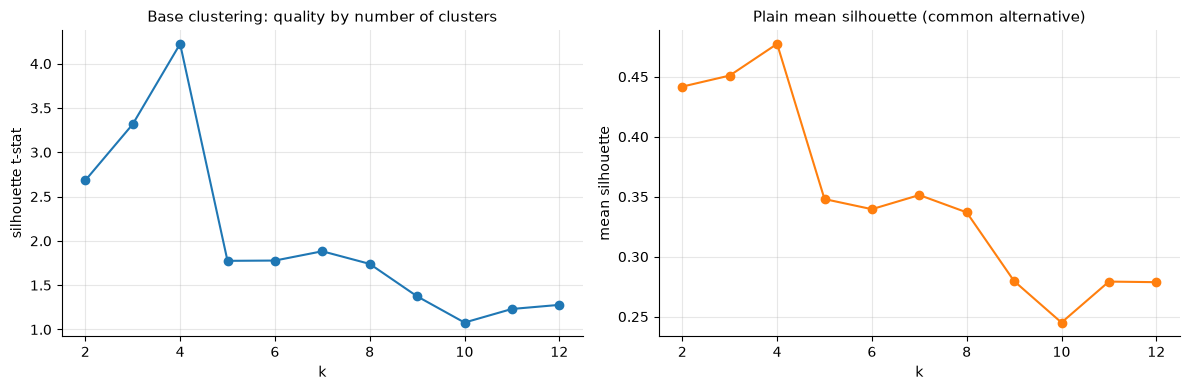

ONC found 4 clusters; k with best t-stat: 4; k with best mean silhouette: 4
cluster 0: SPY, QQQ, IWM, VTV, VUG, EFA, EEM, VGK, EWJ, FXI, HYG, EMB, VNQ
cluster 1: AGG, TLT, IEF, SHY, LQD, TIP
cluster 2: GLD, SLV
cluster 3: USO, DBC


In [5]:
def quality_by_k(corr, max_k=12, seed=0):
    dist = ((1 - pd.DataFrame(corr)) / 2.0) ** 0.5
    out = {}
    for k in range(2, max_k + 1):
        lab = KMeans(k, n_init=10, random_state=seed).fit_predict(dist.values)
        s = silhouette_samples(dist.values, lab)
        out[k] = {"mean silhouette": s.mean(), "silhouette t-stat": s.mean() / s.std()}
    return pd.DataFrame(out).T

qk = quality_by_k(corr_etf)
labels_etf, sil_etf = qt.onc(corr_etf, max_k=12)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
qk["silhouette t-stat"].plot(ax=axes[0], marker="o")
axes[0].set(title="Base clustering: quality by number of clusters", xlabel="k", ylabel="silhouette t-stat")
qk["mean silhouette"].plot(ax=axes[1], marker="o", color="C1")
axes[1].set(title="Plain mean silhouette (common alternative)", xlabel="k", ylabel="mean silhouette")
plt.tight_layout(); plt.show()

print(f"ONC found {labels_etf.nunique()} clusters; k with best t-stat: {int(qk['silhouette t-stat'].idxmax())}; k with best mean silhouette: {int(qk['mean silhouette'].idxmax())}")
for c in sorted(labels_etf.unique()):
    print(f"cluster {c}: {', '.join(labels_etf.index[labels_etf == c])}")

- The t-statistic peaks clearly at k = 4 (about 4.2, against 2.7 at k = 2 and below 1.9 for every k ≥ 5). The plain mean silhouette also peaks at 4 (0.48), so both criteria agree here, and the recursive step finds no weak cluster worth splitting.
- The four groups are economically clear: one large **risk-on** block (all 10 equity ETFs plus HYG, EMB and VNQ, which trade like equities), **Treasuries and investment-grade bonds** (AGG, TLT, IEF, SHY, LQD, TIP), **gold and silver**, and **oil and broad commodities** (USO, DBC).

### Clustered correlation matrix
Reordering the correlation matrix by cluster should show bright blocks on the diagonal and pale areas between blocks.

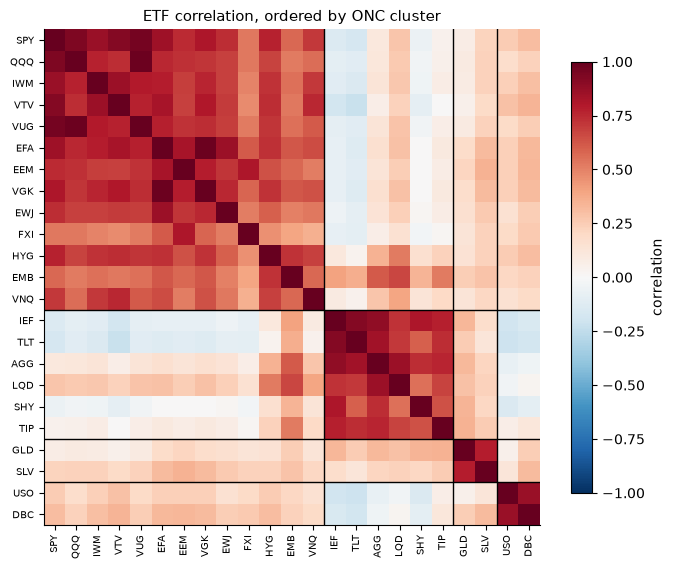

col_0        0  1  2  3
row_0                  
Bonds        2  6  0  0
Intl Equity  5  0  0  0
Real assets  1  0  2  2
US Equity    5  0  0  0

Adjusted Rand index vs asset-class labels: 0.30


In [6]:
def plot_clustered(corr, labels, title, ax=None, groups=None):
    order = labels.sort_values().index
    ax = ax or plt.subplots(figsize=(7, 6))[1]
    im = ax.imshow(corr.loc[order, order].values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(order))); ax.set_yticks(range(len(order)))
    ax.set_xticklabels(order, rotation=90, fontsize=7); ax.set_yticklabels(order, fontsize=7)
    ax.grid(False)
    edges = np.cumsum(labels.sort_values().value_counts(sort=False).sort_index().values) - 0.5
    for e in edges[:-1]:
        ax.axhline(e, color="k", lw=1); ax.axvline(e, color="k", lw=1)
    ax.set_title(title)
    return im

fig, ax = plt.subplots(figsize=(8, 7))
im = plot_clustered(corr_etf, labels_etf, "ETF correlation, ordered by ONC cluster", ax)
fig.colorbar(im, ax=ax, shrink=0.8, label="correlation"); plt.show()

ct = pd.crosstab(etf_group, labels_etf)
print(ct.to_string())
print(f"\nAdjusted Rand index vs asset-class labels: {adjusted_rand_score(etf_group, labels_etf):.2f}")

- The risk-on block is uniformly red (correlations of 0.5–0.95), Treasuries form their own block with near-zero or slightly negative correlation to equities, and the two commodity pairs are distinct.
- The adjusted Rand index (ARI: 1 = identical partitions, 0 = no better than chance) against the asset-class labels is only 0.30. The gap is mostly in the labels. They split equities into US and international, file HYG and EMB under bonds, and lump oil with gold under real assets, while the returns say that all equities and credit move together and that energy and metals are separate. The clustering describes behaviour.

## 5 · Does ONC recover clusters that are known?

On real data the true grouping is unknown, so ONC is tested on simulated returns with a known structure: each asset = √ρ · (its block factor) + √(1−ρ) · (own noise), giving within-block correlation ρ. Two designs:
- **Equal blocks**: 60 assets in 6 blocks of 10, ρ = 0.3 in every block. The easy case.
- **Unequal blocks**: 6 blocks of sizes 4, 6, 8, 10, 12 and 20 with ρ from 0.08 to 0.45. Weak, small groups sit next to strong, large ones, as in real markets.

Methods compared, at sample lengths T = 100 to 1,000 days with 20 draws each:
- **ONC**: the procedure of section 4.
- **ONC + refine**: also re-clusters a single weak cluster (the plain rule acts only when two or more clusters are weak).
- **Single-pass ONC + refine**: one re-clustering step with no recursion, an earlier simplified implementation kept for comparison.
- **k-means + silhouette** and **Ward + silhouette**: the common recipe, choosing k by the best mean silhouette.

Scores: ARI against the true blocks, and the share of draws with exactly 6 clusters.

                                          ARI                   exact k                  
T                                        100   250   500   1000    100   250   500   1000
regime         method                                                                    
equal blocks   ONC                       1.00  1.00  1.00  1.00    1.00  1.00  1.00  1.00
               ONC + refine              0.98  1.00  1.00  1.00    0.65  1.00  0.95  0.95
               Ward + silhouette         0.99  1.00  1.00  1.00    1.00  1.00  1.00  1.00
               k-means + silhouette      1.00  1.00  1.00  1.00    1.00  1.00  1.00  1.00
               single-pass ONC + refine  1.00  1.00  1.00  1.00    1.00  1.00  1.00  1.00
unequal blocks ONC                       0.34  0.34  0.34  0.34    0.00  0.00  0.00  0.00
               ONC + refine              0.67  0.88  0.89  0.95    0.10  0.20  0.40  0.55
               Ward + silhouette         0.88  0.97  0.99  1.00    0.20  0.70  0.90  1.00
          

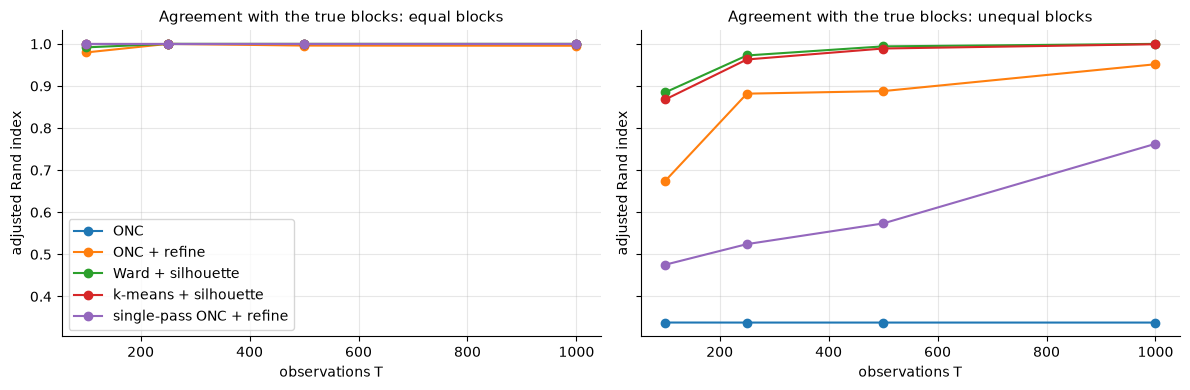

In [7]:
SIZES = {"equal blocks": ([10] * 6, [0.3] * 6), "unequal blocks": ([4, 6, 8, 10, 12, 20], [0.08, 0.10, 0.15, 0.20, 0.30, 0.45])}

def simulate_blocks(regime, T):
    sizes, rhos = SIZES[regime]
    block = np.repeat(np.arange(6), sizes)
    rho = np.array(rhos)[block]
    f = rng.normal(size=(T, 6))
    e = rng.normal(size=(T, len(block)))
    return pd.DataFrame(np.sqrt(rho) * f[:, block] + np.sqrt(1 - rho) * e), block

def best_silhouette(dist, make_labels, max_k=15):
    best, best_lab = -2, None
    for k in range(2, max_k + 1):
        lab = make_labels(k)
        s = silhouette_score(dist, lab, metric="precomputed")
        if s > best:
            best, best_lab = s, lab
    return best_lab

def cluster_all(corr):
    dist = ((1 - corr.values) / 2.0) ** 0.5
    np.fill_diagonal(dist, 0)
    onc_lab, _ = qt.onc(corr, max_k=15, n_init=5)
    onc_r_lab, _ = qt.onc(corr, max_k=15, n_init=5, refine_single=True)
    flat_lab, _ = qt.onc_flat(corr, max_k=15, n_init=5, refine_single=True)
    km_lab = best_silhouette(dist, lambda k: KMeans(k, n_init=5, random_state=0).fit_predict(dist))
    z = linkage(squareform(dist, checks=False), "ward")
    wd_lab = best_silhouette(dist, lambda k: fcluster(z, k, "maxclust"))
    return {"ONC": onc_lab.values, "ONC + refine": onc_r_lab.values, "single-pass ONC + refine": flat_lab.values,
            "k-means + silhouette": km_lab, "Ward + silhouette": wd_lab}

records = []
for regime in SIZES:
    for T in [100, 250, 500, 1000]:
        for rep in range(20):
            x, truth = simulate_blocks(regime, T)
            for name, lab in cluster_all(x.corr()).items():
                records.append({"regime": regime, "T": T, "method": name, "k found": len(np.unique(lab)),
                                "exact k": len(np.unique(lab)) == 6, "ARI": adjusted_rand_score(truth, lab)})
sim = pd.DataFrame(records)
sim_tab = sim.pivot_table(index=["regime", "method"], columns="T", values=["exact k", "ARI"]).round(2)
print(sim_tab.to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, regime in zip(axes, SIZES):
    for m, g in sim[sim.regime == regime].groupby("method"):
        s = g.groupby("T")["ARI"].mean()
        ax.plot(s.index, s.values, marker="o", label=m)
    ax.set(title=f"Agreement with the true blocks: {regime}", xlabel="observations T", ylabel="adjusted Rand index")
axes[0].legend(); plt.tight_layout(); plt.show()

- **Equal blocks**: every method recovers the six blocks (ARI ≥ 0.98) from T = 100. ONC + refine sometimes splits one block too many at T = 100 (exactly 6 clusters in 65% of draws).
- **Unequal blocks**: plain ONC returns 2 clusters in every draw at every T (ARI 0.34). More data does not help, so the cause is the stopping rule. The base step finds the strong blocks as one tight cluster and lumps the weak blocks into one loose cluster. Only that one cluster is below average quality, and the plain rule re-clusters only when two or more are weak, so it stops.
- **Redoing a lone weak cluster recursively** fixes most of the failure: ARI rises from 0.67 at T = 100 to 0.95 at T = 1,000. The single-pass version reaches only 0.48 to 0.76, so the recursion matters. The exact count of 6 is still found in only 10–55% of draws.
- **k-means and Ward with the best mean silhouette** stay ahead (ARI 0.87 to 1.00; exact k in 15–20% of draws at T = 100, 70–75% at 250, 90–95% at 500 and 100% at 1,000). On this design the t-statistic adds nothing over the plain mean silhouette.

## 6 · Does cleaning the correlation matrix change the clusters?

Two cleaning steps can be applied before clustering:
- **Detoning** removes the first principal component, the market factor. Every asset loads on it, so it raises all correlations together and pulls assets into one large group.
- **Denoising** keeps only the eigenvalues that exceed the range pure noise would produce (the Marcenko-Pastur band) and flattens the rest, which removes estimation noise.

ONC is run on four inputs (raw, detoned, denoised, both) for the ETFs over the full history and for the stocks over the last three years. The score is the ARI against asset-class or sector labels, read as a consistency check. For stocks, k-means told the true number of sectors (k = 10) is the reference.

In [8]:
def prepare(corr, q, how):
    c = corr.values
    if how in ("denoised", "denoised + detoned"):
        c, _ = qt.denoise_corr(c, q)
    if how in ("detoned", "denoised + detoned"):
        c = qt.detone_corr(c, 1)
    return pd.DataFrame(c, index=corr.index, columns=corr.columns)

def compare_inputs(returns, group, max_k):
    q = len(returns) / returns.shape[1]
    corr = returns.corr()
    rows = {}
    for how in ["raw", "detoned", "denoised", "denoised + detoned"]:
        c = prepare(corr, q, how)
        lab, _ = qt.onc(c, max_k=max_k, n_init=5)
        lab_r, _ = qt.onc(c, max_k=max_k, n_init=5, refine_single=True)
        rows[how] = {"ONC clusters": lab.nunique(), "ONC ARI": adjusted_rand_score(group, lab),
                     "ONC+refine clusters": lab_r.nunique(), "ONC+refine ARI": adjusted_rand_score(group, lab_r)}
    return pd.DataFrame(rows).T

print("ETFs (all history)")
etf_cmp = compare_inputs(etf, etf_group, 12)
print(etf_cmp.round(2).to_string())

stk3 = stk.iloc[-756:]
print("\nStocks (last 3 years)")
stk_cmp = compare_inputs(stk3, stk_group, 20)
print(stk_cmp.round(2).to_string())

dist_stk = ((1 - stk3.corr()) / 2) ** 0.5
km10 = KMeans(10, n_init=10, random_state=0).fit_predict(dist_stk.values)
print(f"\nk-means with the true k=10 on stocks: ARI {adjusted_rand_score(stk_group, km10):.2f}")

ETFs (all history)
                    ONC clusters  ONC ARI  ONC+refine clusters  ONC+refine ARI
raw                          4.0     0.30                  4.0            0.30
detoned                      8.0     0.63                  8.0            0.63
denoised                     4.0     0.30                  6.0            0.49
denoised + detoned           2.0     0.25                  4.0            0.25

Stocks (last 3 years)
                    ONC clusters  ONC ARI  ONC+refine clusters  ONC+refine ARI
raw                          2.0     0.13                  3.0            0.19
detoned                      2.0     0.12                  3.0            0.18
denoised                     2.0     0.13                  2.0            0.13
denoised + detoned           2.0     0.12                  7.0            0.27

k-means with the true k=10 on stocks: ARI 0.43


- **ETFs: detoning is what matters.** Raw correlation gives 4 clusters (ARI 0.30); removing the market gives 8 clusters and ARI 0.63, because equities and credit are no longer glued together by the common factor. Denoising alone leaves 4 clusters; with the refine option it gives 6 (ARI 0.49).
- Denoising and detoning together collapse the ETFs to 2 clusters (ARI 0.25). Denoising keeps only a few eigenvectors, and removing the first of them leaves a matrix dominated by the next factor (bonds against everything else), so the cleanest split is in two.
- **Stocks: ONC sees only 2 groups** on every input (ARI 0.12–0.13), roughly cyclical against defensive. With refine it finds 2–3 on most inputs and 7 on the denoised and detoned matrix (ARI 0.27). k-means told k = 10 reaches ARI 0.43, so the sector structure is in the correlations but the silhouette t-statistic prefers a coarse split when sector strengths differ, the failure mode of section 5.
- Sector labels are an imperfect yardstick: many stocks trade with their style or factor exposure more than with their sector, so an ARI of 1.0 is not expected.

### The detoned ETF clusters
The detoned ETF partition is the finest structure the method finds on this universe.

cluster 0: SPY, QQQ, VUG   [US Equity]
cluster 1: IWM, VTV   [US Equity]
cluster 2: EFA, VGK, EWJ   [Intl Equity]
cluster 3: EEM, FXI   [Intl Equity]
cluster 4: AGG, TLT, IEF, SHY, LQD, TIP, EMB   [Bonds]
cluster 5: HYG, VNQ   [Bonds, Real assets]
cluster 6: GLD, SLV   [Real assets]
cluster 7: USO, DBC   [Real assets]


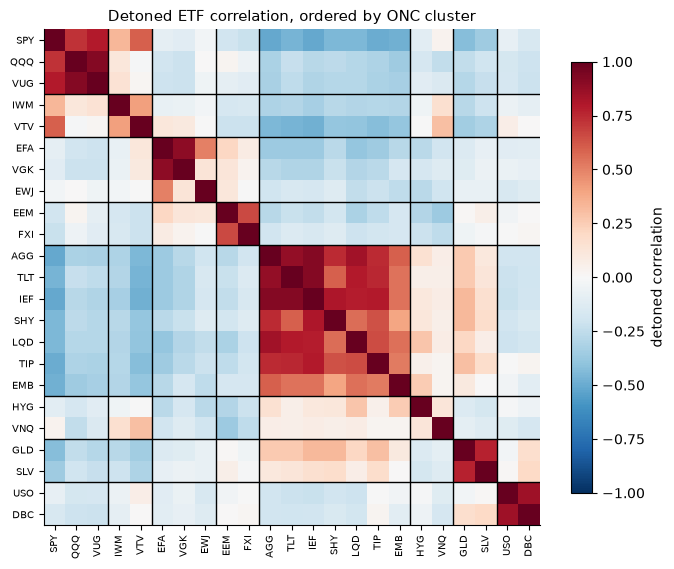

In [9]:
etf_clean = prepare(etf.corr(), len(etf) / etf.shape[1], "detoned")
labels_dt, _ = qt.onc(etf_clean, max_k=12, n_init=5)
for c in sorted(labels_dt.unique()):
    members = labels_dt.index[labels_dt == c]
    print(f"cluster {c}: {', '.join(members)}   [{', '.join(sorted(set(etf_group[members])))}]")

fig, ax = plt.subplots(figsize=(8, 7))
im = plot_clustered(etf_clean, labels_dt, "Detoned ETF correlation, ordered by ONC cluster", ax)
fig.colorbar(im, ax=ax, shrink=0.8, label="detoned correlation"); plt.show()

- The 8 clusters are finer than the asset-class labels and economically interpretable: US large-cap and growth (SPY, QQQ, VUG); US value and small caps (IWM, VTV); developed ex-US (EFA, VGK, EWJ); emerging markets (EEM, FXI); Treasuries and IG bonds with EM debt (AGG, TLT, IEF, SHY, LQD, TIP, EMB); credit and real estate (HYG, VNQ); gold and silver; oil and commodities.
- Style and region splits inside equities appear only once the market factor is removed. On the detoned heatmap, equities show negative correlation to bonds, which is the market factor's absence made visible: what remains is each group's deviation from the common move.

## 7 · Are the clusters stable over time?

A grouping that changes every year cannot anchor a risk budget or a nested portfolio. ONC is re-run on the ETFs over 2-year windows stepped by one year (detoned correlation), and each partition is compared with the previous window's by ARI. References: k-means with a fixed k = 5 on the same windows, and a null that shuffles the asset labels of the second window (expected ARI 0).

            clusters  ARI vs labels  ARI vs previous window  fixed k=5 ARI vs previous  shuffled null
window end                                                                                           
2017-01-03         3           0.25                     NaN                        NaN            NaN
2018-01-03         4           0.41                    0.02                       0.74           0.00
2019-01-04         2           0.39                    0.10                       0.85           0.00
2020-01-06         4           0.46                    0.81                       0.82          -0.00
2021-01-05         7           0.59                    0.39                       0.67           0.00
2022-01-04         7           0.59                    1.00                       1.00           0.00
2023-01-05         2           0.38                    0.25                       0.75          -0.00
2024-01-08         2           0.25                    0.83                       

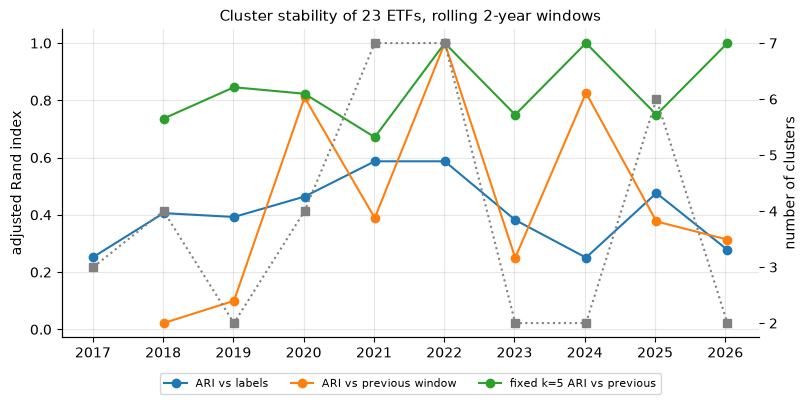

In [10]:
win, step = 504, 252
rows, prev, prev_km, lab_hist = [], None, None, {}
for end in range(win, len(etf) + 1, step):
    w = etf.iloc[end - win:end]
    c = prepare(w.corr(), win / w.shape[1], "detoned")
    lab, _ = qt.onc(c, max_k=12, n_init=5)
    km = pd.Series(KMeans(5, n_init=10, random_state=0).fit_predict(((1 - c) / 2) ** 0.5), index=c.index)
    lab_hist[w.index[-1].date()] = lab
    row = {"window end": w.index[-1].date(), "clusters": lab.nunique(), "ARI vs labels": adjusted_rand_score(etf_group, lab)}
    if prev is not None:
        row["ARI vs previous window"] = adjusted_rand_score(prev, lab)
        row["fixed k=5 ARI vs previous"] = adjusted_rand_score(prev_km, km)
        row["shuffled null"] = np.mean([adjusted_rand_score(prev, rng.permutation(lab.values)) for _ in range(200)])
    rows.append(row)
    prev, prev_km = lab, km
stab = pd.DataFrame(rows).set_index("window end")
print(stab.round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 4))
stab[["ARI vs labels", "ARI vs previous window", "fixed k=5 ARI vs previous"]].plot(ax=ax, marker="o")
ax2 = ax.twinx(); stab["clusters"].plot(ax=ax2, color="grey", ls=":", marker="s", label="clusters (right)")
ax2.set_ylabel("number of clusters"); ax2.grid(False)
ax.set(title="Cluster stability of 23 ETFs, rolling 2-year windows", ylabel="adjusted Rand index", xlabel="")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=8)
plt.show()

- The ONC cluster count moves between 2 and 7 from one window to the next (3, 4, 2, 4, 7, 7, 2, 2, 6, 2). Agreement with the previous window averages 0.45 and ranges from 0.02 to 1.00; it is high only when two consecutive windows land on the same k.
- When ONC picks 6–7 clusters, agreement with asset classes is 0.48–0.59; when it picks 2, it is 0.25–0.39.
- A fixed k = 5 agrees with the previous window at 0.84 on average (0.67 to 1.00). The instability comes from the choice of k, not from the correlations themselves. The shuffled null scores 0.00, so even the unstable ONC partitions carry real information.

## Conclusions

**What holds**
- Use √(½(1−ρ)) as the distance: zero triangle violations against 9% of ETF triples for 1−ρ.
- Mutual information catches non-linear links (x²: MI 0.67 vs \|ρ\| 0.02), but on daily ETF returns it ranks pairs almost exactly like correlation (0.92), so correlation suffices for liquid assets.
- Detoning before clustering a multi-asset universe reveals real structure: 4 → 8 ETF groups, ARI 0.30 → 0.63, with clean region and style splits.

**What does not**
- ONC's plain stopping rule fails when group strengths differ: 2 clusters in every unequal-block draw and on 90 stocks. Recursive re-clustering of a lone weak cluster lifts simulated ARI from 0.34 to 0.67–0.95 but still trails k-means or Ward with the best mean silhouette (0.87–1.00).
- The automatic k is unstable through time (2 to 7 across windows, agreement 0.45 vs 0.84 for a fixed k).

**Practical rule.** Detone first, run ONC to propose k, cross-check with k-means or Ward at the best mean silhouette, and fix k once it is economically sensible and stable across windows. Then let the data assign members.

**Next steps.** Track membership stability weighted by portfolio weight; test hierarchical clustering on the detoned stock matrix; compare cluster-based risk budgets with sector-based ones out of sample.